# Setup

In [2]:
import pairadigm as pdm
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.optim import AdamW
from torch.amp import autocast, GradScaler
from typing import List, Tuple, Optional, Union, Dict
import numpy as np
from tqdm import tqdm
import json
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
from pairadigm import Pairadigm
import copy
import random
import polars as pl

import sys
from datetime import datetime
import os

In [3]:
# Setup logging to file for tmux sessions

# Create logs directory if it doesn't exist
# os.makedirs("../Model Training/training_logs", exist_ok=True)

# # Create log file with timestamp
# log_file = f"../Model Training/training_logs/training_log_emobank_reward_{datetime.now().strftime('%Y%m%d_%H%M%S')}.txt"

# # Redirect stdout and stderr to log file while keeping console output
# class Tee:
#     def __init__(self, *files):
#         self.files = files
#     def write(self, obj):
#         for f in self.files:
#             f.write(obj)
#             f.flush()
#     def flush(self):
#         for f in self.files:
#             f.flush()

# log_file_handle = open(log_file, 'w')
# sys.stdout = Tee(sys.stdout, log_file_handle)
# sys.stderr = Tee(sys.stderr, log_file_handle)

# print(f"Logging to: {log_file}")
# print(f"Training started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

In [4]:
# Set random seeds for reproducibility
def set_seeds(seed: int = 42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Detect best device available
def get_best_device(cuda_index: int = 0, verbose: bool = True):
    """Detect best device: CUDA (with index) > MPS > CPU"""
    if torch.cuda.is_available():
        if cuda_index < torch.cuda.device_count():
            device = torch.device(f"cuda:{cuda_index}")
            device_name = f"cuda:{cuda_index}"
            if verbose:
                try:
                    print(f"Using NVIDIA GPU {cuda_index}: {torch.cuda.get_device_name(cuda_index)}")
                except Exception:
                    print(f"Using NVIDIA GPU {cuda_index}")
        else:
            raise ValueError(f"CUDA device {cuda_index} not available. Available devices: 0 to {torch.cuda.device_count()-1}")

    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        device_name = "mps"
        if verbose:
            print("Using Apple Silicon GPU via MPS")
    else:
        device = torch.device("cpu")
        device_name = "cpu"
        if verbose:
            print("No GPU found, using CPU")
    return device, device_name

# Example usage
set_seeds(42)
device, device_name = get_best_device(cuda_index=0, verbose=True)

Using NVIDIA GPU 0: NVIDIA RTX 4000 Ada Generation


# Prep Data

In [5]:
# Load with Polars (faster)
emobank = pl.read_csv("../Data/emobank.csv").to_pandas()
V = pl.read_csv("../Data/pairwise_probs_V.csv").to_pandas() # NOTE: we are not using it for training the reward model, will use the original EmoBank data instead
A = pl.read_csv("../Data/pairwise_probs_A.csv").to_pandas()
D = pl.read_csv("../Data/pairwise_probs_D.csv").to_pandas()

# Drop the Unnamed column if it exists
for df in [emobank, A, D]:
    if 'Unnamed: 0' in df.columns:
        df.drop(columns=['Unnamed: 0'], inplace=True)

!!! NOTE: DECIDED to NOT use the same pairs as in EmoPair and just take a random set of pairs generated from EmoBank training split to have more data for training the reward model. 

## Generate Pairs for Train - Dev - Test Set

In [6]:
def join_texts(pairwise_probs, emobank):
    """Join the texts from emobank to the pairwise probabilities dataframe."""

    texts = emobank[['id', 'text']]

    merge = pairwise_probs.merge(
        texts,
        left_on="Item_A",
        right_on="id",
        how="left"
    ).rename(columns={"text": "Text_A"}).drop(columns=["id"]).merge(
        texts,
        left_on="Item_B",
        right_on="id",
        how="left"
    ).rename(columns={"text": "Text_B"}).drop(columns=["id"])

    return merge

In [7]:
def prepare_pairs(split: str, A, D, emobank, seed_num: int = 42):
    """
    Prepare pairs from emopair/emobank dataset with A/D probabilities and gold V scores.
    
    Args:
        split: 'train', 'dev', or 'test' split from emobank
        A, D: DataFrames with pairwise probabilities for Arousal and Dominance
        emobank: DataFrame with text data and gold V/A/D scores
        seed_num: random seed for reproducibility
        
    Returns:
        DataFrame with pairs including:
        - Item_A, Item_B: IDs
        - Text_A, Text_B: text content
        - V_A, V_B: gold Valence scores from EmoBank
        - Probability_A_greater_B_A, Probability_A_greater_B_D: pairwise probabilities
    """
    set_seeds(seed_num)
    num_pairs_per_item = 10
    if split == 'train':
        num_pairs_per_item = 12

    # Get IDs 
    emobank_subset = emobank[emobank['split'] == split].copy()
    
    subset_ids = emobank_subset['id'].to_list()
    subset_pairs = pdm.pair_items(subset_ids, 
                                  num_pairs_per_item=num_pairs_per_item,
                                  random_seed=seed_num)
    
    # Rename for consistency
    subset_pairs.rename(columns={'item1': 'Item_A', 'item2': 'Item_B'}, inplace=True)
    subset_pairs = join_texts(subset_pairs, emobank)
    
    # Add gold Valence scores from EmoBank (pointwise)
    v_scores = emobank[['id', 'V']].copy()
    subset_pairs = subset_pairs.merge(
        v_scores,
        left_on='Item_A',
        right_on='id',
        how='left'
    ).rename(columns={'V': 'V_A'}).drop(columns=['id'])
    
    subset_pairs = subset_pairs.merge(
        v_scores,
        left_on='Item_B',
        right_on='id',
        how='left'
    ).rename(columns={'V': 'V_B'}).drop(columns=['id'])
    
    # Merge A, D probabilities with order-aware matching (pairwise)
    for df, dim_name in zip([A, D], ['A', 'D']):
        prob_col = f'Probability_A_greater_B_{dim_name}'
        ind_col = f'A_better_indicator_{dim_name}'
        
        # Try direct match (same order: subset A=df A, subset B=df B)
        direct = subset_pairs.merge(
            df[['Item_A', 'Item_B', 'Probability_A_greater_B', 'A_better_indicator']],
            on=['Item_A', 'Item_B'],
            how='left'
        )
        
        # Try reverse match (flipped order: subset A=df B, subset B=df A)
        df_flipped = df[['Item_A', 'Item_B', 'Probability_A_greater_B', 'A_better_indicator']].copy()
        df_flipped.rename(columns={'Item_A': 'Item_B', 'Item_B': 'Item_A'}, inplace=True)
        
        # Flip the probability and indicator for reversed pairs
        df_flipped['Probability_A_greater_B'] = 1.0 - df_flipped['Probability_A_greater_B']
        df_flipped['A_better_indicator'] = 1 - df_flipped['A_better_indicator']
        
        reverse = subset_pairs[['Item_A', 'Item_B']].merge(
            df_flipped,
            on=['Item_A', 'Item_B'],
            how='left'
        )
        
        # Combine: use direct match where available, fall back to reverse
        subset_pairs[prob_col] = direct['Probability_A_greater_B'].fillna(
            reverse['Probability_A_greater_B']
        )
        subset_pairs[ind_col] = direct['A_better_indicator'].fillna(
            reverse['A_better_indicator']
        )
    
    return subset_pairs


In [8]:
train_set_pairs = prepare_pairs('train', A, D, emobank, seed_num=42)
train_set_pairs

,Item_A,Item_B,Text_A,Text_B,V_A,V_B,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,SemEval_81,SemEval_810,Police warn of child exploitation online,Fuel spill may lead to missing jet,2.00,2.70,0.58,1.0,0.58,1.0
1,Nathans_Bylichka_53042_53076,Seedbombing_2772_2864,"I bet his hide-out is nearby, too.",No one I know is getting digg'd or favrd yet f...,3.00,3.00,0.68,1.0,0.38,0.0
2,IntroDublin_7137_7284,SemEval_949,The universities attract students from all ove...,China detains 2 after body parts found in mail,3.44,2.30,0.36,0.0,0.28,0.0
3,A_defense_of_Michael_Moore_26673_26683,HistoryLasVegas_7356_7515,Conclusion,"One year after the auction, the population of ...",3.00,3.12,0.40,0.0,0.50,0.0
4,The_Black_Willow_4423_4462,captured_moments_35271_35326,"Shall I never finish a story in peace?""",I hit him with the back of my hand.,2.50,2.60,0.30,0.0,0.14,0.0
...,...,...,...,...,...,...,...,...,...,...
55428,SemEval_823,wsj_2465_1649_1766,Peter Jackson will never work for me again,They want to terrify the press and in particul...,2.33,2.60,0.42,0.0,0.34,0.0
55429,Nathans_Bylichka_42854_42890,detroit_13997_14072,She has good blood under her cheeks.,"Lumpy, I'm not a Democrat and I don't much app...",3.22,2.50,0.50,1.0,0.42,0.0
55430,Ant_Robot_13448_13536,SemEval_207,A table of the sensors and their relation to t...,"Flooding washes out road to Valdez, Alaska",3.10,2.57,0.50,0.0,0.60,1.0
55431,Homosexuality_10382_10524,Nathans_Bylichka_51611_51626,More and more people are beginning to believe ...,"“No, I saw him!",3.20,2.70,0.12,0.0,0.40,0.0


In [9]:
eval_set_pairs = prepare_pairs('dev', A, D, emobank, seed_num=42)
eval_set_pairs

,Item_A,Item_B,Text_A,Text_B,V_A,V_B,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,Seedbombing_5975_6064,Uprooted_Farming-on-Sand_1534_1557,"My discontent is the mother of invention, and ...","""This is what happens,""",3.00,2.40,0.66,1.0,0.50,0.0
1,20020731-nyt_34626_34663,SemEval_1382,"""Experience. Excellence. Carl McCall""",Cousin: Gunman was Srebrenica survivor,3.50,2.88,0.66,1.0,0.70,1.0
2,Fermentation_Eminent-Domain_8129_8183,wsj_0032_376_452,"John, Good of you to comment and good to have ...",Montedison currently owns about 72% of Erbamon...,3.50,3.00,0.80,1.0,0.80,1.0
3,Homosexuality_19050_19100,captured_moments_3940_3990,"Woods, Daniel S. Telephone interview. 6 June 2...","She said, ""It's beautiful, isn't it, Señor Fly...",3.00,3.60,0.30,0.0,0.40,0.0
4,WhereToHongKong_56281_56446,captured_moments_12994_13054,"Guangzhou, with a population of more than 5 mi...",how does one speak to one's future self?,3.00,3.00,0.32,0.0,0.50,1.0
...,...,...,...,...,...,...,...,...,...,...
5765,Bartok_6460_6654,Black_and_white_10174_10292,The perfect fourth in fact generates much of t...,For this reason white walls are favored over c...,3.12,3.13,0.88,1.0,0.84,1.0
5766,anth_essay_4_18387_18702,cable_spool_fort_667_695,"In Guatemala, they are largely comprised of th...",It smelled like first grade.,2.90,3.11,0.60,1.0,0.50,0.0
5767,Nathans_Bylichka_11606_11659,Nathans_Bylichka_26060_26148,"As we kept driving, the anxiety grew more pron...",“we regret that we cannot take up your kind of...,2.60,3.00,0.84,1.0,0.76,1.0
5768,115CVL036_714_788,hotel-california_26699_26747,Where else would that many people turn if CCI ...,The lightscreen had proved singularly unhelpful.,2.90,2.40,0.60,1.0,0.60,1.0


In [10]:
# mask = (A['Item_A'] == 'IFAW1_4581_4663') & (A['Item_B'] == 'Nathans_Bylichka_29397_29482')
mask = (A['Item_B'] == 'IFAW1_4581_4663') & (A['Item_A'] == 'Nathans_Bylichka_29397_29482')
A[mask]

,,Dimension,Item_A,Item_B,Probability_A_greater_B,A_better_indicator
38635343,115906030,A,Nathans_Bylichka_29397_29482,IFAW1_4581_4663,0.76,1


In [11]:
test_set_pairs = prepare_pairs('test', A, D, emobank, seed_num=42)
test_set_pairs

,Item_A,Item_B,Text_A,Text_B,V_A,V_B,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,hotel-california_24439_24514,hotel-california_30009_30053,"From the looks on my companions' faces, I knew...","“That doesn't answer my question,” she said.",3.00,2.40,0.60,1.0,0.60,1.0
1,Ohio_Steel_7949_8077,WhereToHongKong_26220_26504,The Coalition drafter letters to the Lykes Com...,The lookout point at Lok Ma Chau was once know...,3.12,3.00,0.70,1.0,0.50,0.0
2,Fermentation_HR5034_12069_12195,SemEval_78,Tom said... Seems like some old geezers are fi...,"Bangladesh ferry sinks, 15 dead",2.60,1.57,0.84,1.0,0.78,1.0
3,A_defense_of_Michael_Moore_7288_7473,A_defense_of_Michael_Moore_7523_7651,"""I guess I don't see that specific connection ...",Moore is not from Colorado -- his question is ...,2.60,2.88,0.82,1.0,0.52,1.0
4,SemEval_1037,detroit_12913_12919,China: Cheney shores up the trilateral alliance,"""Free""",3.10,3.60,0.24,0.0,0.40,0.0
...,...,...,...,...,...,...,...,...,...,...
5743,defenders5_6808_6957,defenders5_7211_7304,1. SIGN the enclosed Citizens’ Advisory Ballot...,"And then, mail it back to us along with your e...",2.78,3.00,0.40,0.0,0.50,0.0
5744,HistoryLasVegas_8686_8887,Seedbombing_1551_1573,Construction on Hoover Dam (originally Boulder...,Customize it yourself.,3.00,3.10,0.50,1.0,0.30,0.0
5745,wsj_0168_144_203,wsj_0171_864_970,The sale represents 10.2% of Meridian's shares...,New loans continue to slow; they were $6.6 mil...,3.10,2.70,0.60,1.0,0.68,1.0
5746,Fermentation_Eminent-Domain_5533_5650,Fermentation_Eminent-Domain_97_347,"I completely agree with you when you state: ""S...","I was disappointed, though not surprised, to s...",2.80,2.60,0.50,1.0,0.60,1.0


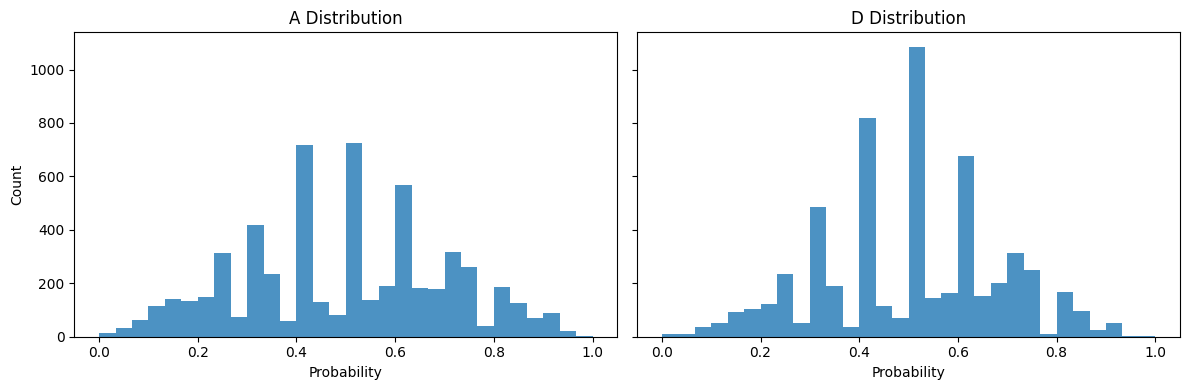

In [12]:
import matplotlib.pyplot as plt

prob_cols = [
    "Probability_A_greater_B_A",
    "Probability_A_greater_B_D",
]
labels = ["A", "D"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, col, label in zip(axes, prob_cols, labels):
    eval_set_pairs[col].plot(kind="hist", bins=30, ax=ax, alpha=0.8)
    ax.set_title(f"{label} Distribution")
    ax.set_xlabel("Probability")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

# Build Model

### Key Updates to the Reward Model Framework

**Architecture:** Separate heads for Valence (pointwise) vs. Arousal/Dominance (pairwise)

This model splits emotional dimensions based on data quality:
- **Valence**: Uses gold-standard EmoBank scores → Direct linear head (no MLP) → MSE loss
- **Arousal & Dominance**: Uses validated LLM pairwise annotations → Separate linear head → Bradley-Terry loss

**Model Components:**
- `valence_head`: Linear(hidden_size, 1) - Predicts 1-5 Likert scale directly from [CLS] embedding
- `arousal_dominance_head`: Linear(hidden_size, 2) - Predicts relative scores for pairwise comparisons
- No MLP layers - direct transformation from embeddings for interpretabil ity

**Data Format:**
- Each training sample: `(text_A, text_B, V_A, V_B, prob_A, prob_D)`
  - `V_A`, `V_B`: Gold Valence scores from EmoBank (1-5 scale)
  - `prob_A`, `prob_D`: LLM-generated pairwise probabilities that A > B

**Training Loss:**
```python
loss_V = MSE(valence_A, V_A) + MSE(valence_B, V_B)  # Pointwise regression
loss_A = -[p * log(σ(r_A - r_B)) + (1-p) * log(σ(r_B - r_A))]  # Bradley-Terry
loss_D = -[p * log(σ(r_A - r_B)) + (1-p) * log(σ(r_B - r_A))]  # Bradley-Terry
total_loss = loss_V + loss_A + loss_D
```

**Scoring:**
- `score_text()` returns: `{'valence': float, 'arousal': float, 'dominance': float}`
- Valence scores are directly interpretable on 1-5 scale (after training on gold data)
- Arousal/Dominance scores need normalization for comparison with EmoBank

**Evaluation:**
- Valence: MSE loss (pointwise)
- Arousal/Dominance: Pairwise accuracy + Bradley-Terry loss

**Why This Design?**
1. **Valence has gold labels** (EmoBank) → train directly on absolute scores
2. **A/D have LLM pairwise judgments** → train on relative preferences
3. **No MLP** → simpler model, fewer parameters, more interpretable
4. **Separate heads** → each dimension optimized appropriately for its data type 

## Setup

In [13]:
def make_tuples(data):
    """Convert dataframe to list of tuples with V gold scores and A/D probabilities.
    
    Args:
        data: DataFrame with columns Text_A, Text_B, V_A, V_B, Probability_A_greater_B_A, Probability_A_greater_B_D
        
    Returns:
        List of tuples: (text_A, text_B, V_A, V_B, prob_A, prob_D)
    """
    return list(
        zip(
            data['Text_A'].tolist(),
            data['Text_B'].tolist(),
            data['V_A'].tolist(),
            data['V_B'].tolist(),
            data['Probability_A_greater_B_A'].tolist(),
            data['Probability_A_greater_B_D'].tolist()
        )
    )

make_tuples(train_set_pairs)[:2]  # Show first 2 examples

[('Police warn of child exploitation online',
  'Fuel spill may lead to missing jet',
  2.0,
  2.7,
  0.58,
  0.58),
 ('I bet his hide-out is nearby, too.',
  "No one I know is getting digg'd or favrd yet for throwing color and scent around the ghetto.",
  3.0,
  3.0,
  0.6799999999999999,
  0.38)]

In [14]:
# Functions for evaluation of regression metrics on the splits to compare with PERT, etc.
def calculate_metrics(predictions: np.ndarray, targets: np.ndarray) -> Dict[str, float]:
    """Compute MAE, R2, and Pearson metrics (overall and per-dimension)."""
    mae = mean_absolute_error(targets, predictions)
    r2 = r2_score(targets, predictions)
    pearson = pearsonr(targets.flatten(), predictions.flatten())[0]

    mae_per_dim = [mean_absolute_error(targets[:, i], predictions[:, i]) for i in range(3)]
    r2_per_dim = [r2_score(targets[:, i], predictions[:, i]) for i in range(3)]
    pearson_per_dim = [pearsonr(targets[:, i], predictions[:, i])[0] for i in range(3)]

    return {
        'mae': mae,
        'r2': r2,
        'mae_valence': mae_per_dim[0],
        'mae_arousal': mae_per_dim[1],
        'mae_dominance': mae_per_dim[2],
        'r2_valence': r2_per_dim[0],
        'r2_arousal': r2_per_dim[1],
        'r2_dominance': r2_per_dim[2],
        'pearson': pearson,
        'pearson_valence': pearson_per_dim[0],
        'pearson_arousal': pearson_per_dim[1],
        'pearson_dominance': pearson_per_dim[2]
    }

def evaluate_regression_on_split(
    emobank_df: pd.DataFrame,
    split: str,
    reward_model: 'RewardModel',
    normalization_params: Optional[Dict[str, Dict[str, float]]] = None,
    batch_size: int = 32,
    scale_min: float = 1.0,
    scale_max: float = 5.0
) -> Dict[str, float]:
    """
    Score texts for a split and compute regression metrics vs gold V/A/D.
    
    Args:
        emobank_df: EmoBank dataframe
        split: 'train', 'dev', or 'test'
        reward_model: Trained reward model
        normalization_params: Pre-computed min/max params (if None, normalize within split)
        batch_size: Batch size for scoring
        scale_min: Minimum of target scale
        scale_max: Maximum of target scale
    """
    subset = emobank_df[emobank_df['split'] == split].copy()
    subset = subset.dropna(subset=['text', 'V', 'A', 'D'])
    if subset.empty:
        raise ValueError(f"No rows found for split '{split}' with V/A/D labels.")

    texts = subset['text'].tolist()
    targets = subset[['V', 'A', 'D']].values.astype(np.float32)
    
    # Get raw predictions
    preds_dict = reward_model.score_batch(texts, batch_size=batch_size)
    
    # Normalize predictions
    if normalization_params is not None:
        preds_dict = reward_model.normalize_scores_with_params(
            preds_dict, normalization_params, scale_min, scale_max
        )
    else:
        # Fallback: normalize within this split (not recommended for comparison)
        print(f"Warning: Normalizing {split} split independently. For fair comparison, provide normalization_params.")
        for dim in ['valence', 'arousal', 'dominance']:
            preds_dict[dim] = reward_model.normalize_scores(
                preds_dict[dim], scale_min, scale_max
            )
    
    predictions = np.vstack([
        preds_dict['valence'],
        preds_dict['arousal'],
        preds_dict['dominance']
    ]).T

    return calculate_metrics(predictions, targets)

In [ ]:
class RewardModel:
    """
    Unified class for training and using a reward model for text scoring.
    
    This class handles:
    - Model initialization and configuration
    - Dataset creation and management
    - Training loop with pairwise comparisons
    - Scoring individual texts or batches
    - Score normalization
    """
    
    def __init__(
        self,
        model_name: str = "answerdotai/ModernBERT-large",
        dropout: float = 0.1,
        max_length: int = 384,
        device: Optional[str] = None,
        Pairadigm: Optional['Pairadigm'] = None,
        seed: int = 42
    ):
        """
        Initialize the reward model trainer.
        
        Args:
            model_name: HuggingFace model identifier
            dropout: Dropout rate for reward head
            max_length: Maximum sequence length for tokenization
            device: Device to use ('cuda', 'cpu', or None for auto-detect)
        """
        # Set seeds at model initialization
        set_seeds(seed)

        self.model_name = model_name
        self.max_length = max_length
        if device:
            self.device = device
        elif torch.cuda.is_available():
            self.device = 'cuda'
        elif torch.backends.mps.is_available():
            self.device = 'mps'
        else:
            self.device = 'cpu'
        print(f"Model using device: {self.device}")
        
        # Initialize tokenizer
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        
        # Initialize model
        self.model = self._build_model(dropout)
        self.model.to(self.device)

        # If a Pairadigm instance is provided, link it
        self.pairadigm = Pairadigm
        
        # Training state
        self.optimizer = None
        self.scheduler = None
        self.scaler = GradScaler('cuda') # For mixed precision training
        self.training_history = []
        # self.loss_weights = {'V': 0.4, 'A': 0.3, 'D': 0.3}
    
    def _build_model(self, dropout: float) -> nn.Module:
        """Build the reward model architecture with separate heads for V (pointwise) and A/D (pairwise)."""
        encoder = AutoModel.from_pretrained(self.model_name)
        hidden_size = encoder.config.hidden_size
        
        # Create complete model
        model = nn.Module()
        model.encoder = encoder
        model.dropout = nn.Dropout(dropout)
        
        # Direct linear transformation from embeddings (no MLP)
        # Separate head for Valence (pointwise regression, 1-5 scale)
        model.valence_head = nn.Linear(hidden_size, 1)
        # Separate head for Arousal and Dominance (pairwise comparison, 2 outputs)
        model.arousal_dominance_head = nn.Linear(hidden_size, 2)

        # Xavier initialization for both heads
        nn.init.xavier_uniform_(model.valence_head.weight, gain=1.0)
        nn.init.zeros_(model.valence_head.bias)
        nn.init.xavier_uniform_(model.arousal_dominance_head.weight, gain=1.0)
        nn.init.zeros_(model.arousal_dominance_head.bias)
        
        # Add forward method
        def forward(input_ids, attention_mask):
            outputs = model.encoder(input_ids=input_ids, attention_mask=attention_mask)
            pooled_output = outputs.last_hidden_state[:, 0, :]  # [CLS] token embedding
            pooled_output = model.dropout(pooled_output)
            
            # Valence: (batch_size, 1) - pointwise prediction
            valence = model.valence_head(pooled_output)
            # Arousal/Dominance: (batch_size, 2) - pairwise comparison
            arousal_dominance = model.arousal_dominance_head(pooled_output)
            
            return valence, arousal_dominance
        
        model.forward = forward
        return model

    @staticmethod
    def _uncertainty_weight(prob: torch.Tensor, min_weight: float = 0.25, power: float = 0.5) -> torch.Tensor:
        """Compute softened informativeness weights from pairwise probabilities.

        Base informativeness is |2 * (p - 0.5)| in [0, 1]. We soften it by:
        - applying a square-root transform (power < 1) to reduce harsh downweighting near 0.5
        - adding a minimum floor so uncertain pairs still contribute
        """
        base = (2 * (prob - 0.5)).abs().clamp(0.0, 1.0)
        softened = base.pow(power)
        return min_weight + (1.0 - min_weight) * softened
    
    def prepare_data(
        self,
        pairs: Optional[List[Tuple[str, str, Union[int, float]]]] = None,
        batch_size: int = 16,
        shuffle: bool = True,
        decision_col: str = "decision",
        score_col: str = "Bradley_Terry_Score",
        margins: bool = True,
        test_size: float = 0.15,
        eval_size: float = 0.15,
        stratify: Optional[List] = None,
        random_state: Optional[int] = 42
    ) -> Dict[str, DataLoader]:
        """
        Prepare training, evaluation, and test data from pairwise comparisons.

        Args:
            pairs: Optional list of (text_winner, text_loser, margin) tuples. If None and a Pairadigm instance is linked, will use Pairadigm.
            batch_size: Batch size for training
            shuffle: Whether to shuffle the training data
            decision_col: Column name for decision in pairwise_df
            score_col: Column name for scores in scored_df
            margins: Whether to compute margins from scores
            test_size: Proportion of data for test set (default 0.15)
            eval_size: Proportion of data for eval set (default 0.15)
            stratify: Optional list of labels for stratified splitting
            random_state: Random seed for reproducibility

        Returns:
            Dictionary with 'train', 'eval', and 'test' DataLoaders
        """
        if pairs is None and self.pairadigm:
            pairs = self._prepare_pairadigm(
                decision_col=decision_col, 
                score_col=score_col, 
                margins=margins
            )
        elif pairs is None:
            raise ValueError("No pairs provided and no Pairadigm instance linked.")
        
        # Split data: first split into train+eval and test
        train_eval_pairs, test_pairs = train_test_split(
            pairs,
            test_size=test_size,
            stratify=stratify,
            random_state=random_state
        )
        
        # Then split train+eval into train and eval
        # Adjust eval_size to be relative to train+eval size
        adjusted_eval_size = eval_size / (1 - test_size)
        train_pairs, eval_pairs = train_test_split(
            train_eval_pairs,
            test_size=adjusted_eval_size,
            stratify=None,  # stratify only on first split
            random_state=random_state
        )
        
        print(f"Data split - Train: {len(train_pairs)}, Eval: {len(eval_pairs)}, Test: {len(test_pairs)}")
        
        # Create datasets and dataloaders
        train_dataset = self._PairwiseDataset(train_pairs, self.tokenizer, self.max_length)
        eval_dataset = self._PairwiseDataset(eval_pairs, self.tokenizer, self.max_length)
        test_dataset = self._PairwiseDataset(test_pairs, self.tokenizer, self.max_length)
        
        return {
            'train': DataLoader(train_dataset, batch_size=batch_size, shuffle=shuffle),
            'eval': DataLoader(eval_dataset, batch_size=batch_size, shuffle=False),
            'test': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
        }
    
    class _PairwiseDataset(Dataset):
        """Internal dataset class for pairwise comparisons with V/A/D probabilities."""
        
        def __init__(self, pairs, tokenizer, max_length):
            self.pairs = pairs
            self.tokenizer = tokenizer
            self.max_length = max_length
        
        def __len__(self):
            return len(self.pairs)
        
        def __getitem__(self, idx):
            # Expect tuples: (text_A, text_B, V_A, V_B, prob_A, prob_D)
            text_A, text_B, V_A, V_B, prob_A, prob_D = self.pairs[idx]
            
            encoding_A = self.tokenizer(
                text_A,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            encoding_B = self.tokenizer(
                text_B,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            return {
                'input_ids_A': encoding_A['input_ids'].squeeze(0),
                'attention_mask_A': encoding_A['attention_mask'].squeeze(0),
                'input_ids_B': encoding_B['input_ids'].squeeze(0),
                'attention_mask_B': encoding_B['attention_mask'].squeeze(0),
                'V_A': torch.tensor(V_A, dtype=torch.float),
                'V_B': torch.tensor(V_B, dtype=torch.float),
                'prob_A': torch.tensor(prob_A, dtype=torch.float),
                'prob_D': torch.tensor(prob_D, dtype=torch.float)
            }

    def train(
        self,
        train_loader: DataLoader,
        eval_loader: DataLoader,
        epochs: int = 5,
        learning_rate: float = 2e-5,
        weight_decay: float = 0.01,
        warmup_steps: int = 100,
        log_interval: int = 50,
        early_stopping_patience: int = 3,
        accumulation_steps: int = 1
    ):
        """
        Train the reward model on pairwise comparison data with optional early stopping and gradient accumulation.

        Args:
            train_loader: DataLoader with training pairs (mini-batch size)
            eval_loader: DataLoader for evaluation (required for early stopping)
            epochs: Number of training epochs
            learning_rate: Learning rate for optimizer
            warmup_steps: Number of warmup steps for scheduler
            log_interval: Log metrics every N steps
            early_stopping_patience: Number of epochs with no improvement on eval loss before stopping early.
                                     Set to None or 0 to disable early stopping.
            accumulation_steps: Number of gradient accumulation steps (effective_batch_size = mini_batch_size * accumulation_steps)
        Returns:
            The model (self.model) restored to the best-performing weights observed on eval data.
        """
        self.model.train()
        
        # Setup optimizer and scheduler
        self.optimizer = AdamW(
            self.model.parameters(), 
            lr=learning_rate, 
            weight_decay=weight_decay
        )
        num_update_steps_per_epoch = math.ceil(len(train_loader) / accumulation_steps)
        total_steps = num_update_steps_per_epoch * epochs
        self.scheduler = get_linear_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps
        )

        # Early stopping bookkeeping
        best_state = None
        best_eval_loss = float('inf')
        epochs_without_improve = 0
        use_early_stopping = bool(early_stopping_patience and eval_loader is not None and early_stopping_patience > 0)
        
        for epoch in range(epochs):
            # # Freeze encoder on first epoch, gradually unfreeze after
            # if epoch == 0:
            #     for param in self.model.encoder.parameters():
            #         param.requires_grad = False
            # elif epoch <= 2:  # Gradual unfreezing
            #     for i, layer in enumerate(self.model.encoder.encoder.layer):
            #         if i >= len(self.model.encoder.encoder.layer) - 4:  # Unfreeze last 4 layers
            #             for param in layer.parameters():
            #                 param.requires_grad = True
            # else:
            #     for param in self.model.encoder.parameters():
            #         param.requires_grad = True
            
            epoch_loss = 0
            progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
            self.optimizer.zero_grad()  # Zero gradients at start of epoch
            grad_norm = float('nan')
            accumulated_since_step = 0
            
            for step, batch in enumerate(progress_bar):
                # Perform forward/backward pass, accumulate gradients
                loss = self._training_step(batch, accumulation_steps)
                epoch_loss += loss
                accumulated_since_step += 1
                
                # Update weights after accumulation_steps
                if (step + 1) % accumulation_steps == 0:
                    self.scaler.unscale_(self.optimizer)
                    grad_norm = torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                    scale_before = self.scaler.get_scale()
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                    scale_after = self.scaler.get_scale()
                    if scale_after >= scale_before:
                        self.scheduler.step()
                    self.optimizer.zero_grad()
                    accumulated_since_step = 0
                
                if (step + 1) % log_interval == 0:
                    avg_loss = epoch_loss / (step + 1)
                    progress_bar.set_postfix({'loss': f'{avg_loss:.4f}', 'grad_norm': f'{grad_norm:.4f}'})

            # Flush remainder gradients when number of steps is not divisible by accumulation_steps
            if accumulated_since_step > 0:
                self.scaler.unscale_(self.optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                scale_before = self.scaler.get_scale()
                self.scaler.step(self.optimizer)
                self.scaler.update()
                scale_after = self.scaler.get_scale()
                if scale_after >= scale_before:
                    self.scheduler.step()
                self.optimizer.zero_grad()
            
            avg_epoch_loss = epoch_loss / len(train_loader)
            epoch_metrics = {'epoch': epoch + 1, 'train_loss': avg_epoch_loss}
            
            print(f"Epoch {epoch + 1} - Train Loss: {avg_epoch_loss:.4f}")
            
            # Evaluation
            if eval_loader:
                eval_metrics = self.evaluate(eval_loader)
                epoch_metrics.update(eval_metrics)
                print(f"Epoch {epoch + 1} - Eval Loss: {eval_metrics['eval_loss']:.4f} | Accuracy: {eval_metrics['eval_accuracy']:.2%}")
                print(f"  Loss - V (MSE): {eval_metrics['eval_loss_V']:.4f} | A: {eval_metrics['eval_loss_A']:.4f} | D: {eval_metrics['eval_loss_D']:.4f}")
                print(f"  Acc  - A: {eval_metrics['eval_accuracy_A']:.2%} | D: {eval_metrics['eval_accuracy_D']:.2%}")
                
                # Check for improvement on eval_loss and save best model
                current_eval_loss = eval_metrics.get('eval_loss', float('inf'))
                if current_eval_loss < best_eval_loss:
                    best_eval_loss = current_eval_loss
                    # store a CPU copy of the state dict
                    best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
                    epochs_without_improve = 0
                    print(f"  New best model found (eval_loss improved to {best_eval_loss:.4f}).")
                else:
                    epochs_without_improve += 1
                    print(f"  No improvement for {epochs_without_improve} epoch(s).")
            
            else:
                # If no eval_loader provided, we can't do early stopping / track best by eval
                best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
            
            self.training_history.append(epoch_metrics)

            # Early stopping check
            if use_early_stopping and epochs_without_improve >= early_stopping_patience:
                print(f"Early stopping triggered after {epoch + 1} epochs (no improvement in eval loss for {early_stopping_patience} epochs).")
                break
        
        # Restore best model weights if we tracked them
        if best_state is not None:
            # move tensors back to device as needed when loading
            device_state = {k: v.to(self.device) for k, v in best_state.items()}
            self.model.load_state_dict(device_state)
            print("Best model weights restored based on eval data.")
        
        return self.model
    
    def _training_step(self, batch, accumulation_steps: int = 1) -> float:
        """Single training step with MSE for V (pointwise) and Bradley-Terry for A/D (pairwise).
        
        Args:
            batch: Dictionary containing input_ids, attention_masks, V_A, V_B (gold scores), prob_A, prob_D
            accumulation_steps: Number of steps to accumulate gradients over
            
        Returns:
            Loss value for this step
        """
        batch = {key: value.to(self.device) for key, value in batch.items()}
        
        with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
            # Forward pass for both texts
            valence_A, ad_A = self.model(
                batch['input_ids_A'],
                batch['attention_mask_A']
            )
            valence_B, ad_B = self.model(
                batch['input_ids_B'],
                batch['attention_mask_B']
            )
            
            # Valence: Pointwise MSE loss against gold scores (1-5 scale)
            loss_V = nn.functional.mse_loss(valence_A.squeeze(), batch['V_A']) + \
                     nn.functional.mse_loss(valence_B.squeeze(), batch['V_B'])
            
            # Arousal & Dominance: Pairwise Bradley-Terry loss with soft cross-entropy
            # loss = -[p * log(σ(r_A - r_B)) + (1-p) * log(σ(r_B - r_A))]
            # with informativeness weighting: weight = |2 * (p - 0.5)|
            eps = 1e-7  # For numerical stability
            
            # Arousal (index 0 in arousal_dominance output)
            prob_A = batch['prob_A']
            logit_A = ad_A[:, 0] - ad_B[:, 0]
            per_sample_loss_A = -(prob_A * torch.log(torch.sigmoid(logit_A) + eps) + 
                       (1 - prob_A) * torch.log(torch.sigmoid(-logit_A) + eps))
            weight_A = self._uncertainty_weight(prob_A)
            loss_A = (per_sample_loss_A * weight_A).mean()
            
            # Dominance (index 1 in arousal_dominance output)
            prob_D = batch['prob_D']
            logit_D = ad_A[:, 1] - ad_B[:, 1]
            per_sample_loss_D = -(prob_D * torch.log(torch.sigmoid(logit_D) + eps) + 
                       (1 - prob_D) * torch.log(torch.sigmoid(-logit_D) + eps))
            weight_D = self._uncertainty_weight(prob_D)
            loss_D = (per_sample_loss_D * weight_D).mean()
            
            # Total loss (equal weighting for now, can tune later)
            total_loss = (loss_V + loss_A + loss_D) / accumulation_steps
        
        self.scaler.scale(total_loss).backward()
        return total_loss.item() * accumulation_steps
    
    def _compute_pairwise_accuracy(self, batch) -> Dict[str, float]:
        """Compute pairwise accuracy for A/D dimensions (excluding ties)."""
        batch = {key: value.to(self.device) for key, value in batch.items()}
        
        with torch.no_grad():
            _, ad_A = self.model(batch['input_ids_A'], batch['attention_mask_A'])
            _, ad_B = self.model(batch['input_ids_B'], batch['attention_mask_B'])

        prob_A = batch['prob_A']
        prob_D = batch['prob_D']

        correct_A = ((prob_A > 0.5) & (ad_A[:, 0] > ad_B[:, 0])) | \
                    ((prob_A < 0.5) & (ad_B[:, 0] > ad_A[:, 0]))
        correct_D = ((prob_D > 0.5) & (ad_A[:, 1] > ad_B[:, 1])) | \
                    ((prob_D < 0.5) & (ad_B[:, 1] > ad_A[:, 1]))

        non_tie_A = (prob_A != 0.5)
        non_tie_D = (prob_D != 0.5)

        accuracy_A = correct_A[non_tie_A].float().mean().item() if non_tie_A.any() else 0.0
        accuracy_D = correct_D[non_tie_D].float().mean().item() if non_tie_D.any() else 0.0

        return {
            'accuracy_A': accuracy_A,
            'accuracy_D': accuracy_D,
            'accuracy_overall': (accuracy_A + accuracy_D) / 2
        }
    
    def evaluate(self, eval_loader: DataLoader) -> Dict[str, float]:
        """Evaluate the model using MSE for V (pointwise) and Bradley-Terry for A/D (pairwise)."""
        self.model.eval()
        total_loss = 0
        losses_by_dim = {'V': 0, 'A': 0, 'D': 0}
        
        total_correct_A = 0
        total_correct_D = 0
        total_count_A = 0
        total_count_D = 0
        
        eps = 1e-7
        
        with torch.no_grad():
            for batch in eval_loader:
                batch = {key: value.to(self.device) for key, value in batch.items()}
                
                valence_A, ad_A = self.model(
                    batch['input_ids_A'],
                    batch['attention_mask_A']
                )
                valence_B, ad_B = self.model(
                    batch['input_ids_B'],
                    batch['attention_mask_B']
                )
                
                # Valence: MSE loss against gold scores
                loss_V = nn.functional.mse_loss(valence_A.squeeze(), batch['V_A']) + \
                         nn.functional.mse_loss(valence_B.squeeze(), batch['V_B'])
                
                # Arousal: Bradley-Terry loss with soft cross-entropy
                prob_A = batch['prob_A']
                logit_A = ad_A[:, 0] - ad_B[:, 0]
                per_sample_loss_A = -(prob_A * torch.log(torch.sigmoid(logit_A) + eps) + 
                          (1 - prob_A) * torch.log(torch.sigmoid(-logit_A) + eps))
                weight_A = self._uncertainty_weight(prob_A)
                loss_A = (per_sample_loss_A * weight_A).mean()
                
                # Dominance: Bradley-Terry loss with soft cross-entropy
                prob_D = batch['prob_D']
                logit_D = ad_A[:, 1] - ad_B[:, 1]
                per_sample_loss_D = -(prob_D * torch.log(torch.sigmoid(logit_D) + eps) + 
                          (1 - prob_D) * torch.log(torch.sigmoid(-logit_D) + eps))
                weight_D = self._uncertainty_weight(prob_D)
                loss_D = (per_sample_loss_D * weight_D).mean()
                
                batch_loss = loss_V + loss_A + loss_D
                total_loss += batch_loss.item()
                losses_by_dim['V'] += loss_V.item()
                losses_by_dim['A'] += loss_A.item()
                losses_by_dim['D'] += loss_D.item()
                
                # Pairwise accuracy for A and D only (V is pointwise)
                correct_A = ((prob_A > 0.5) & (ad_A[:, 0] > ad_B[:, 0])) | \
                           ((prob_A < 0.5) & (ad_B[:, 0] > ad_A[:, 0]))
                correct_D = ((prob_D > 0.5) & (ad_A[:, 1] > ad_B[:, 1])) | \
                           ((prob_D < 0.5) & (ad_B[:, 1] > ad_A[:, 1]))
                
                # Exclude ties (prob == 0.5) from accuracy computation
                non_tie_A = (prob_A != 0.5)
                non_tie_D = (prob_D != 0.5)
                
                total_correct_A += correct_A[non_tie_A].sum().item()
                total_correct_D += correct_D[non_tie_D].sum().item()
                total_count_A += non_tie_A.sum().item()
                total_count_D += non_tie_D.sum().item()
        
        self.model.train()
        
        accuracy_A = total_correct_A / max(total_count_A, 1)
        accuracy_D = total_correct_D / max(total_count_D, 1)
        accuracy_overall = (accuracy_A + accuracy_D) / 2  # Only A and D have pairwise accuracy
        
        return {
            'eval_loss': total_loss / len(eval_loader),
            'eval_loss_V': losses_by_dim['V'] / len(eval_loader),
            'eval_loss_A': losses_by_dim['A'] / len(eval_loader),
            'eval_loss_D': losses_by_dim['D'] / len(eval_loader),
            'eval_accuracy': accuracy_overall,
            'eval_accuracy_A': accuracy_A,
            'eval_accuracy_D': accuracy_D
        }
    
    def score_text(self, text: str) -> Dict[str, float]:
        """
        Score a single text item across all three dimensions (V, A, D).
        
        Args:
            text: Text to score
            
        Returns:
            Dictionary with 'valence', 'arousal', 'dominance' scores
        """
        self.model.eval()
        
        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        with torch.no_grad():
            valence, arousal_dominance = self.model(
                encoding['input_ids'].to(self.device),
                encoding['attention_mask'].to(self.device)
            )
        
        return {
            'valence': valence[0, 0].item(),
            'arousal': arousal_dominance[0, 0].item(),
            'dominance': arousal_dominance[0, 1].item()
        }
    
    def score_batch(self, texts: List[str], batch_size: int = 32) -> Dict[str, np.ndarray]:
        """
        Score multiple texts efficiently across all three dimensions.
        
        Args:
            texts: List of texts to score
            batch_size: Number of texts to process at once
            
        Returns:
            Dictionary with 'valence', 'arousal', 'dominance' arrays
        """
        self.model.eval()
        scores_V = []
        scores_A = []
        scores_D = []
        
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i + batch_size]
            encodings = self.tokenizer(
                batch_texts,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            with torch.no_grad():
                valence, arousal_dominance = self.model(
                    encodings['input_ids'].to(self.device),
                    encodings['attention_mask'].to(self.device)
                )
            
            scores_V.extend(valence[:, 0].cpu().numpy())
            scores_A.extend(arousal_dominance[:, 0].cpu().numpy())
            scores_D.extend(arousal_dominance[:, 1].cpu().numpy())
        
        return {
            'valence': np.array(scores_V),
            'arousal': np.array(scores_A),
            'dominance': np.array(scores_D)
        }
    
    def fit_normalization_params(
        self,
        texts: List[str],
        batch_size: int = 32
    ) -> Dict[str, Dict[str, float]]:
        """
        Fit normalization parameters using percentiles for robustness."""
        scores = self.score_batch(texts, batch_size=batch_size)
        
        params = {}
        for dim in ['valence', 'arousal', 'dominance']:
            dim_scores = scores[dim]
            # Use 1st/99th percentiles instead of raw min/max
            p_low = float(np.percentile(dim_scores, 1))
            p_high = float(np.percentile(dim_scores, 99))
            params[dim] = {'min': p_low, 'max': p_high}
        
        return params
    
    def normalize_scores_with_params(
        self,
        scores: Dict[str, np.ndarray],
        params: Dict[str, Dict[str, float]],
        scale_min: float = 1.0,
        scale_max: float = 5.0,
        clip: bool = True
    ) -> Dict[str, np.ndarray]:
        """
        Normalize scores using pre-computed parameters.
        
        Args:
            scores: Dictionary with 'valence', 'arousal', 'dominance' arrays
            params: Min/max parameters for each dimension from fit_normalization_params
            scale_min: Minimum value of output scale (EmoBank uses 1)
            scale_max: Maximum value of output scale (EmoBank uses 5)
            clip: Whether to clip values to [scale_min, scale_max]
            
        Returns:
            Dictionary with normalized scores
        """
        normalized = {}
        
        for dim in ['valence', 'arousal', 'dominance']:
            dim_min = params[dim]['min']
            dim_max = params[dim]['max']
            
            if dim_max == dim_min:
                # If no variance, use midpoint
                normalized[dim] = np.full_like(scores[dim], (scale_min + scale_max) / 2)
            else:
                # Linear scaling
                norm = (scores[dim] - dim_min) / (dim_max - dim_min)
                norm = norm * (scale_max - scale_min) + scale_min
                
                if clip:
                    norm = np.clip(norm, scale_min, scale_max)
                
                normalized[dim] = norm
        
        return normalized
    
    def normalize_scores(
        self,
        scores: np.ndarray,
        scale_min: float = 0.0,
        scale_max: float = 1.0
    ) -> np.ndarray:
        """
        Normalize raw reward scores to a desired scale.
        This normalizes within the provided scores (relative scaling).
        For consistent scaling across splits, use normalize_scores_with_params instead.
        
        Args:
            scores: Raw scores to normalize
            scale_min: Minimum value of output scale
            scale_max: Maximum value of output scale
            
        Returns:
            Normalized scores
        """
        score_min = scores.min()
        score_max = scores.max()
        
        if score_max == score_min:
            return np.full_like(scores, (scale_min + scale_max) / 2)
        
        normalized = (scores - score_min) / (score_max - score_min)
        normalized = normalized * (scale_max - scale_min) + scale_min
        
        return normalized
    
    def test_model(self, test_loader: DataLoader) -> Dict[str, float]:
        """Evaluate the model on the test set using MSE for V and Bradley-Terry for A/D."""
        print("\n" + "="*60)
        print("Running Test Evaluation (V, A, D)")
        print("="*60)
        
        self.model.eval()
        total_loss = 0
        losses_by_dim = {'V': 0, 'A': 0, 'D': 0}
        
        total_correct_A = 0
        total_correct_D = 0
        total_count_A = 0
        total_count_D = 0
        
        eps = 1e-7
        
        with torch.no_grad():
            for batch in tqdm(test_loader, desc="Testing"):
                batch = {key: value.to(self.device) for key, value in batch.items()}
                
                valence_A, ad_A = self.model(
                    batch['input_ids_A'],
                    batch['attention_mask_A']
                )
                valence_B, ad_B = self.model(
                    batch['input_ids_B'],
                    batch['attention_mask_B']
                )
                
                # Valence: MSE loss
                loss_V = nn.functional.mse_loss(valence_A.squeeze(), batch['V_A']) + \
                         nn.functional.mse_loss(valence_B.squeeze(), batch['V_B'])
                
                # Arousal: Bradley-Terry loss
                prob_A = batch['prob_A']
                logit_A = ad_A[:, 0] - ad_B[:, 0]
                per_sample_loss_A = -(prob_A * torch.log(torch.sigmoid(logit_A) + eps) + 
                          (1 - prob_A) * torch.log(torch.sigmoid(-logit_A) + eps))
                weight_A = self._uncertainty_weight(prob_A)
                loss_A = (per_sample_loss_A * weight_A).mean()
                
                # Dominance: Bradley-Terry loss
                prob_D = batch['prob_D']
                logit_D = ad_A[:, 1] - ad_B[:, 1]
                per_sample_loss_D = -(prob_D * torch.log(torch.sigmoid(logit_D) + eps) + 
                          (1 - prob_D) * torch.log(torch.sigmoid(-logit_D) + eps))
                weight_D = self._uncertainty_weight(prob_D)
                loss_D = (per_sample_loss_D * weight_D).mean()
                
                batch_loss = loss_V + loss_A + loss_D
                total_loss += batch_loss.item()
                losses_by_dim['V'] += loss_V.item()
                losses_by_dim['A'] += loss_A.item()
                losses_by_dim['D'] += loss_D.item()
                
                # Pairwise accuracy for A and D only
                correct_A = ((prob_A > 0.5) & (ad_A[:, 0] > ad_B[:, 0])) | \
                           ((prob_A < 0.5) & (ad_B[:, 0] > ad_A[:, 0]))
                correct_D = ((prob_D > 0.5) & (ad_A[:, 1] > ad_B[:, 1])) | \
                           ((prob_D < 0.5) & (ad_B[:, 1] > ad_A[:, 1]))
                
                non_tie_A = (prob_A != 0.5)
                non_tie_D = (prob_D != 0.5)
                
                total_correct_A += correct_A[non_tie_A].sum().item()
                total_correct_D += correct_D[non_tie_D].sum().item()
                total_count_A += non_tie_A.sum().item()
                total_count_D += non_tie_D.sum().item()
        
        test_loss = total_loss / len(test_loader)
        test_loss_V = losses_by_dim['V'] / len(test_loader)
        test_loss_A = losses_by_dim['A'] / len(test_loader)
        test_loss_D = losses_by_dim['D'] / len(test_loader)
        
        accuracy_A = total_correct_A / max(total_count_A, 1)
        accuracy_D = total_correct_D / max(total_count_D, 1)
        accuracy_overall = (accuracy_A + accuracy_D) / 2
        
        print(f"\nTest Results:")
        print(f"  Total Loss: {test_loss:.4f} | Accuracy (A/D): {accuracy_overall:.2%}")
        print(f"  Valence   - Loss (MSE): {test_loss_V:.4f}")
        print(f"  Arousal   - Loss: {test_loss_A:.4f} | Acc: {accuracy_A:.2%}")
        print(f"  Dominance - Loss: {test_loss_D:.4f} | Acc: {accuracy_D:.2%}")
        print("\n" + "="*60 + "\n")
        
        results = {
            'test_loss': test_loss,
            'test_loss_V': test_loss_V,
            'test_loss_A': test_loss_A,
            'test_loss_D': test_loss_D,
            'test_accuracy': accuracy_overall,
            'test_accuracy_A': accuracy_A,
            'test_accuracy_D': accuracy_D
        }
        
        return results
    
    def save(self, path: str):
        """Save model and training state."""
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict() if self.optimizer else None,
            'scheduler_state_dict': self.scheduler.state_dict() if self.scheduler else None,
            'training_history': self.training_history,
            'config': {
                'model_name': self.model_name,
                'max_length': self.max_length
            }
        }, path)
        print(f"Model saved to {path}")
    
    def load(self, path: str):
        """Load model and training state."""
        checkpoint = torch.load(path, map_location=self.device)
        self.model.load_state_dict(checkpoint['model_state_dict'])
        
        if checkpoint['optimizer_state_dict'] and self.optimizer:
            self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        
        if checkpoint['scheduler_state_dict'] and self.scheduler:
            self.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        self.training_history = checkpoint.get('training_history', [])
        print(f"Model loaded from {path}")

    def push_to_hub(self, repo_id: str, private: bool = True):
        """
        Push the trained model to HuggingFace Hub.
        
        Args:
            repo_id: Repository ID in format "username/repo-name"
            private: Whether to make the repository private (default True)
        """
        from huggingface_hub import create_repo, upload_folder
        import os
        
        # Create a temporary directory for the model files
        temp_dir = f"./temp_model_{repo_id.split('/')[-1]}"
        os.makedirs(temp_dir, exist_ok=True)
        
        try:
            # Save encoder, tokenizer, and both heads
            self.model.encoder.save_pretrained(os.path.join(temp_dir, "encoder"))
            self.tokenizer.save_pretrained(temp_dir)
            torch.save(
                {
                    'valence_head': self.model.valence_head.state_dict(),
                    'arousal_dominance_head': self.model.arousal_dominance_head.state_dict()
                },
                os.path.join(temp_dir, "task_heads.pt")
            )
            
            # Save metadata
            metadata = {
                'model_name': self.model_name,
                'max_length': self.max_length,
                'training_history': self.training_history
            }
            with open(os.path.join(temp_dir, "training_metadata.json"), 'w') as f:
                json.dump(metadata, f, indent=2)
            
            # Create and upload to Hub
            create_repo(repo_id, private=private, exist_ok=True)
            upload_folder(repo_name=repo_id, folder_path=temp_dir, repo_type="model")
            
            print(f"Model successfully pushed to HuggingFace Hub: https://huggingface.co/{repo_id}")
        
        finally:
            # Clean up temporary directory
            import shutil
            if os.path.exists(temp_dir):
                shutil.rmtree(temp_dir)

## Run

In [ ]:
# Train the reward model using the prepared pairwise data
learning_rate = 1e-5
weight_decay = 0.2
epochs = 20
patience = 11
dropout = 0.4
batch_size = 16  # Mini-batch size that fits in GPU memory
accumulation_steps = 4  # Gradient accumulation steps (effective batch size = 16 * 4 = 64)
max_length = 256
seed_num = 42

effective_batch_size = batch_size * accumulation_steps
print(f"Training parameters - Epochs: {epochs}, LR: {learning_rate}, Weight Decay: {weight_decay}, Patience: {patience}, Dropout: {dropout}")
print(f"Batch Configuration - Mini-batch Size: {batch_size}, Accumulation Steps: {accumulation_steps}, Effective Batch Size: {effective_batch_size}, Seed: {seed_num}")

Training parameters - Epochs: 10, LR: 2e-05, Weight Decay: 0.1, Patience: 5, Dropout: 0.2
Batch Configuration - Mini-batch Size: 16, Accumulation Steps: 4, Effective Batch Size: 64, Seed: 42


In [25]:
print("Initializing Reward Model...")
reward_model = RewardModel(
    model_name="roberta-large",
    dropout=dropout,
    max_length=max_length,
    device=device 
)
print("Reward Model initialized.")

print("Preparing data loaders...")
num_workers = 4 if torch.cuda.is_available() else 0

# Convert to tuples format (V uses gold scores, A/D use probabilities)
train_tuples = make_tuples(train_set_pairs)
eval_tuples = make_tuples(eval_set_pairs)
test_tuples = make_tuples(test_set_pairs)

# Create datasets manually
train_dataset = reward_model._PairwiseDataset(train_tuples, reward_model.tokenizer, reward_model.max_length)
eval_dataset = reward_model._PairwiseDataset(eval_tuples, reward_model.tokenizer, reward_model.max_length)
test_dataset = reward_model._PairwiseDataset(test_tuples, reward_model.tokenizer, reward_model.max_length)

# Calculate warmup steps based on effective batches (after accumulation)
warmup_steps = int(0.02 * (len(train_dataset) / (batch_size * accumulation_steps)) * epochs)
log_interval = 50

# Create dataloaders with fixed generator for reproducibility
generator = torch.Generator()
generator.manual_seed(seed_num)

data_loaders = {
    'train': DataLoader(train_dataset, batch_size=batch_size, shuffle=True, 
                       generator=generator, worker_init_fn=lambda _: set_seeds(seed_num)),
    'eval': DataLoader(eval_dataset, batch_size=batch_size, shuffle=False),
    'test': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
}

print("Data loaders ready.")
print(f"Train pairs: {len(train_tuples)}")
print(f"Eval pairs: {len(eval_tuples)}")
print(f"Test pairs: {len(test_tuples)}")

Initializing Reward Model...
Model using device: cuda:0


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Reward Model initialized.
Preparing data loaders...
Data loaders ready.
Train pairs: 55433
Eval pairs: 5770
Test pairs: 5748


In [ ]:
date = datetime.now().strftime("%Y%m%d")

In [ ]:
# Save training arguments for reproducibility
date = datetime.now().strftime("%Y%m%d")

print("Saving training arguments...")
os.makedirs("../Results/trained models", exist_ok=True)
training_args = {
    'model_name': reward_model.model_name,
    'num_epochs': epochs,
    'batch_size': batch_size,
    'accumulation_steps': accumulation_steps,
    'effective_batch_size': effective_batch_size,
    'learning_rate': learning_rate,
    'device': device_name,
    'weight_decay': weight_decay,
    'warmup_steps': warmup_steps,
    'dropout': dropout,
    'max_length': max_length,
    'seed': seed_num,
    'patience': patience,
    'log_interval': log_interval
}
with open(f"../Results/trained models/emobank_reward_model_training_args_{date}.json", "w") as f:
    json.dump(training_args, f, indent=4)

In [ ]:
print("Starting training...")
try:
    emobank_reward = reward_model.train(
        train_loader=data_loaders['train'],
        eval_loader=data_loaders['eval'],
        epochs=epochs,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        warmup_steps=warmup_steps,
        log_interval=log_interval,
        early_stopping_patience=patience,
        accumulation_steps=accumulation_steps
    )
    
    # Save immediately after training
    reward_model.save(f"../Results/trained models/emobank_reward_model_{date}.pth")
    
except Exception as e:
    print(f"Training failed: {e}")
    # Save checkpoint even if failed
    reward_model.save(f"../Results/trained models/emobank_reward_model_checkpoint_{date}.pth")
    raise

print("Training completed.")

# Save Results

In [ ]:
# After loading the best model, evaluate on test set
test_results = reward_model.test_model(data_loaders['test'])

In [ ]:
# Fit normalization parameters on training data
print("\nFitting normalization parameters on training data...")
train_texts = emobank[emobank['split'] == 'train']['text'].tolist()
normalization_params = reward_model.fit_normalization_params(train_texts, batch_size=32)
print(f"Normalization parameters:")
for dim in ['valence', 'arousal', 'dominance']:
    print(f"  {dim.capitalize()}: min={normalization_params[dim]['min']:.4f}, max={normalization_params[dim]['max']:.4f}")

# Save normalization parameters
with open(f"../Results/trained models/emobank_reward_model_norm_params_{date}.json", "w") as f:
    json.dump(normalization_params, f, indent=4)
print(f"Normalization parameters saved.")

# Compute regression-style metrics for comparison against gold V/A/D
print("\nComputing regression metrics vs gold V/A/D...")
regression_metrics_test = evaluate_regression_on_split(
    emobank_df=emobank,
    split='test',
    reward_model=reward_model,
    normalization_params=normalization_params,
    batch_size=32,
    scale_min=1.0,
    scale_max=5.0
)
regression_metrics_dev = evaluate_regression_on_split(
    emobank_df=emobank,
    split='dev',
    reward_model=reward_model,
    normalization_params=normalization_params,
    batch_size=32,
    scale_min=1.0,
    scale_max=5.0
)
print(f"Regression Metrics (dev): {regression_metrics_dev}")
print(f"Regression Metrics (test): {regression_metrics_test}")

In [ ]:
# Save metrics
metrics_payload = {
    'dev': {k: float(v) for k, v in regression_metrics_dev.items()},
    'test': {k: float(v) for k, v in regression_metrics_test.items()}
}
with open(f"../Results/trained models/emobank_reward_model_regression_metrics_{date}.json", "w") as f:
    json.dump(metrics_payload, f, indent=4)

In [ ]:
# Save test results
test_results_df = pd.DataFrame([test_results])
test_results_df.to_csv(f"../Results/trained models/emobank_reward_model_test_results_{date}.csv", index=False)

In [ ]:
# Save the trained model
reward_model.save(f"../Results/trained models/emobank_reward_model_{date}.pth")

In [ ]:
# Save training history to CSV
history_df = pd.DataFrame(reward_model.training_history)
history_df.to_csv(f"../Results/trained models/emobank_reward_model_training_history_{date}.csv", index=False)

In [ ]:
# Clean up memory after testing
import gc

print("Cleaning up memory...")
del emobank_reward
del data_loaders
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Available: {torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)}")
print("Memory cleanup complete.")

In [29]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Available: {torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)}")
print("Memory cleanup complete.")

GPU memory freed. Available: 15301638144
Memory cleanup complete.


# Load Trained Model

In [25]:
# Load Model 
trained_model_path = "../Results/trained models/emobank_reward_model_20260216.pth"
reward_model = RewardModel(
    model_name="roberta-large",
    dropout=0.1,
    max_length=256,
    device=device 
)
reward_model.load(trained_model_path)

Model using device: cuda:0


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded from ../Results/trained models/emobank_reward_model_20260216.pth


In [26]:
reward_model.training_history

[{'epoch': 1,
  'train_loss': 0.6809513267852413,
  'eval_loss': 0.6638623577011519,
  'eval_loss_V': 0.23874637771900692,
  'eval_loss_A': 0.22663539311445777,
  'eval_loss_D': 0.19848058701136223,
  'eval_accuracy': 0.5565337476264457,
  'eval_accuracy_V': 0.6355946832383912,
  'eval_accuracy_A': 0.5461764198170206,
  'eval_accuracy_D': 0.4878301398239254},
 {'epoch': 2,
  'train_loss': 0.5874277841756587,
  'eval_loss': 0.6742329077779754,
  'eval_loss_V': 0.23931562524935432,
  'eval_loss_A': 0.23299106779013126,
  'eval_loss_D': 0.20192621469743982,
  'eval_accuracy': 0.5443351170953449,
  'eval_accuracy_V': 0.6257552218194372,
  'eval_accuracy_A': 0.523217676506128,
  'eval_accuracy_D': 0.48403245296046954},
 {'epoch': 3,
  'train_loss': 0.5579262216182433,
  'eval_loss': 0.6748400305092499,
  'eval_loss_V': 0.24228975308171316,
  'eval_loss_A': 0.2310442199555967,
  'eval_loss_D': 0.20150605884711603,
  'eval_accuracy': 0.5459462569768111,
  'eval_accuracy_V': 0.6267909546003798

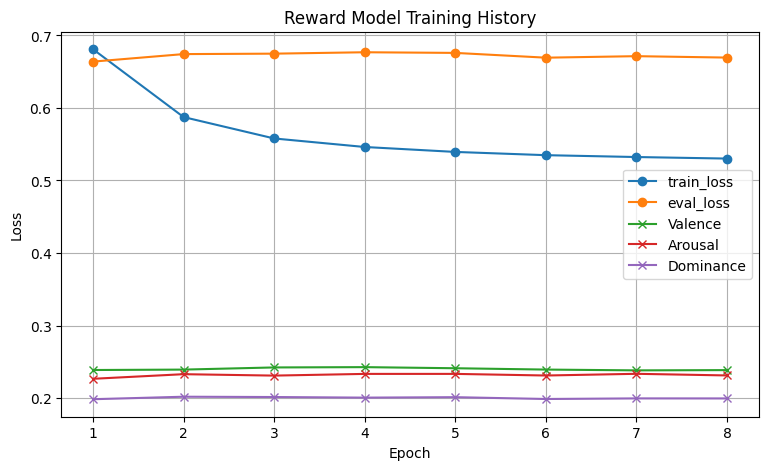

In [27]:
import matplotlib.pyplot as plt

# Convert to DataFrame
history_df = pd.DataFrame(reward_model.training_history)
if history_df.empty:
    print("No training history to plot.")
else:
    # Ensure an epoch column exists
    if 'epoch' not in history_df.columns:
        history_df = history_df.reset_index().rename(columns={'index': 'epoch'})
        history_df['epoch'] = history_df['epoch'] + 1

    plt.figure(figsize=(9,5))
    if 'train_loss' in history_df.columns:
        plt.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='train_loss')
    if 'eval_loss' in history_df.columns:
        plt.plot(history_df['epoch'], history_df['eval_loss'], marker='o', label='eval_loss')
    for col, label in [('eval_loss_V', 'Valence'), ('eval_loss_A', 'Arousal'), ('eval_loss_D', 'Dominance')]:
        if col in history_df.columns:
            plt.plot(history_df['epoch'], history_df[col], marker='x', label=label)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Reward Model Training History')
    plt.legend()
    plt.grid(True)
    plt.show()